# Task 2 — Notebook 3: Split the Data

This notebook divides the labeled orders into **train**, **validation**, and **test** sets.

We use a chronological split because the business goal is to predict future delivery outcomes from historical orders. Later orders must not be used to train a model for earlier orders.

**Input:** `artifacts/tables/02_labeled_table.parquet`

**Outputs:**

- `artifacts/tables/03_train.parquet`
- `artifacts/tables/03_validation.parquet`
- `artifacts/tables/03_test.parquet`


## 1. Imports and paths


In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

import sys

src_dir = Path.cwd().resolve()
while src_dir != src_dir.parent and not (src_dir / "Task2").is_dir():
    src_dir = src_dir.parent
src_dir = src_dir / "Task2" / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from config import find_project_root

PROJECT_ROOT = find_project_root()
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
TABLES_DIR = ARTIFACTS_DIR / "tables"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
CHARTS_DIR = ARTIFACTS_DIR / "charts"

for folder in [TABLES_DIR, REPORTS_DIR, CHARTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

input_path = TABLES_DIR / "02_labeled_table.parquet"
metadata_path = REPORTS_DIR / "03_split_metadata.json"
plot_path = CHARTS_DIR / "03_split_label_balance.png"

if not input_path.exists():
    raise FileNotFoundError(f"Input artifact not found: {input_path}")


## 2. Load and sort the labeled data

The purchase timestamp is used to order the data. We do not shuffle the rows because time order is part of the evaluation design.


In [2]:
df = pd.read_parquet(input_path)

required_columns = ["order_id", "order_purchase_timestamp", "is_late"]
missing_columns = sorted(set(required_columns) - set(df.columns))
assert not missing_columns, f"Missing required columns: {missing_columns}"

# Convert the timestamp before sorting.
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"], errors="coerce"
)

df = (
    df.dropna(subset=["order_purchase_timestamp", "is_late"])
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

assert df["order_id"].is_unique
assert set(df["is_late"].unique()) == {0, 1}

print(f"Rows available: {len(df):,}")
print(f"Date range: {df['order_purchase_timestamp'].min()} to {df['order_purchase_timestamp'].max()}")


Rows available: 96,470
Date range: 2016-09-15 12:16:38 to 2018-08-29 15:00:37


## 3. Create chronological splits

The proportions are 70% train, 15% validation, and 15% test. The validation and test sets contain later orders than the training set, which better represents future prediction.


In [3]:
train_end = int(len(df) * 0.70)
validation_end = int(len(df) * 0.85)

train = df.iloc[:train_end].copy()
validation = df.iloc[train_end:validation_end].copy()
test = df.iloc[validation_end:].copy()

splits = {
    "train": train,
    "validation": validation,
    "test": test,
}

# Confirm that the three groups contain different orders.
assert set(train["order_id"]).isdisjoint(validation["order_id"])
assert set(train["order_id"]).isdisjoint(test["order_id"])
assert set(validation["order_id"]).isdisjoint(test["order_id"])
assert len(train) + len(validation) + len(test) == len(df)


## 4. Compare split sizes and label balance

Because this is a chronological split, the class percentages may differ between periods. We inspect the difference instead of forcing identical class proportions through random stratification.


In [4]:
def split_summary(name, data):
    return {
        "split": name,
        "rows": len(data),
        "start": data["order_purchase_timestamp"].min(),
        "end": data["order_purchase_timestamp"].max(),
        "late_count": int(data["is_late"].sum()),
        "late_percentage": round(data["is_late"].mean() * 100, 2),
    }

split_summary_table = pd.DataFrame([
    split_summary(name, data)
    for name, data in splits.items()
])

display(split_summary_table)


,split,rows,start,end,late_count,late_percentage
0,train,67529,2016-09-15 12:16:38,2018-04-15 20:12:35,6096,9.03
1,validation,14470,2018-04-15 20:17:11,2018-06-21 08:29:29,773,5.34
2,test,14471,2018-06-21 08:41:07,2018-08-29 15:00:37,957,6.61


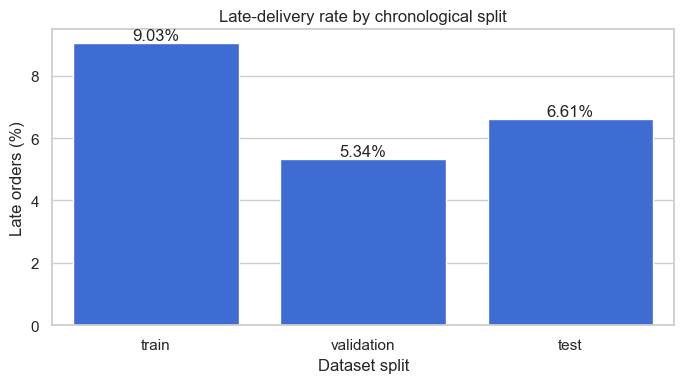

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=split_summary_table,
    x="split",
    y="late_percentage",
    order=["train", "validation", "test"],
    color="#2563eb",
    ax=ax,
)
ax.set_title("Late-delivery rate by chronological split")
ax.set_xlabel("Dataset split")
ax.set_ylabel("Late orders (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()
fig.savefig(plot_path, dpi=150, bbox_inches="tight")


## 5. Save the three split artifacts


In [6]:
output_paths = {
    "train": TABLES_DIR / "03_train.parquet",
    "validation": TABLES_DIR / "03_validation.parquet",
    "test": TABLES_DIR / "03_test.parquet",
}

for name, data in splits.items():
    data.to_parquet(output_paths[name], index=False)

metadata = {
    "strategy": "chronological",
    "proportions": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "reason": "Simulate future prediction and prevent later orders from entering training.",
    "input": str(input_path),
    "outputs": {name: str(path) for name, path in output_paths.items()},
    "split_summary": split_summary_table.astype(str).to_dict(orient="records"),
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved train, validation, and test artifacts.")
print(f"Saved: {metadata_path}")
print(f"Saved: {plot_path}")


Saved train, validation, and test artifacts.
Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\reports\03_split_metadata.json
Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\charts\03_split_label_balance.png


## 6. Final checks


In [7]:
for name, path in output_paths.items():
    assert path.exists() and path.stat().st_size > 0
    reloaded = pd.read_parquet(path)
    assert reloaded["order_id"].is_unique
    assert set(reloaded["is_late"].unique()) == {0, 1}

assert metadata_path.exists()
assert plot_path.exists()
print("ALL NOTEBOOK 3 CHECKS PASSED")


ALL NOTEBOOK 3 CHECKS PASSED
